# Problem 1: RNN, LSTM and GRU

Compare recurrent models on UCI HAR and the adding problem. This notebook is a scaffold: write the required from-scratch cells yourself, then run all experiments and save real outputs.

## Clarification and choices

Ignore the variants table. Pick one hidden size `h` for all three recurrent models and three model seeds. The adding-data seeds are fixed separately at 0, 1 and 2. Record your choices here and in the root README/report.

The email does not mention whether the even/odd student-ID rule for the task 5(c) ablation is also withdrawn. Follow the assignment wording or confirm that detail with the instructor.

In [1]:
# Suggested starting choices only; change these to your own before experiments.
HIDDEN_SIZE = 64
MODEL_SEEDS = (42, 123, 999)
EPOCHS_HAR = 10  # Keep identical across RNN, LSTM and GRU.
EPOCHS_ADDING = 20  # Keep identical within each length/model comparison.
BATCH_SIZE = 128
LEARNING_RATE = 1e-3

assert HIDDEN_SIZE > 0
assert len(MODEL_SEEDS) == 3 and len(set(MODEL_SEEDS)) == 3

## 1.1 Data pipelines

### UCI HAR
Load the nine inertial-signal files in the specified channel order. Hold out four training subjects for validation using the current model seed; never use the official test split to calculate normalization statistics. Plot the six-class balance. Keep the official test subjects separate.

### Adding problem
Use the exact generator in the assignment. For each sequence length 50, 100, 200 and 400, create 10,000 training, 1,000 validation and 1,000 test examples with data seeds 0, 1 and 2. Add assertions for two markers total, one marker in each half, and target equal to the marked-value sum.

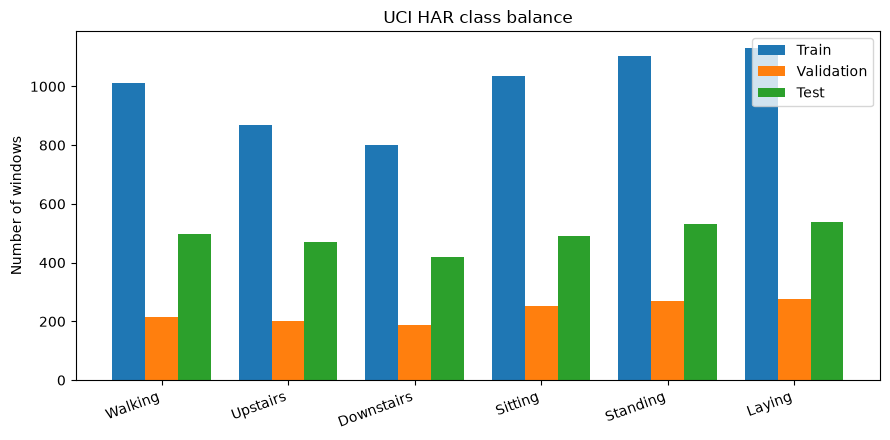

HAR root: C:\Users\SESA870534\Documents\Personal Docs\M.Tech\DNN\Assignment\har_data\UCI HAR Dataset
HAR shapes: (5952, 128, 9) (1400, 128, 9) (2947, 128, 9)
Validation subjects: [3, 16, 22, 23]


In [2]:
from pathlib import Path
import urllib.request
import zipfile

import matplotlib.pyplot as plt
import numpy as np


def find_project_root():
    for base in (Path.cwd().resolve(), *Path.cwd().resolve().parents):
        if (base / "problem1").is_dir() and (base / "results.csv").is_file():
            return base
        for child in base.glob("*_DNN_Assignment"):
            if (child / "problem1").is_dir() and (child / "results.csv").is_file():
                return child
    raise FileNotFoundError("Could not locate the assignment project root.")


PROJECT_ROOT = find_project_root()
HAR_CACHE = PROJECT_ROOT.parent / "har_data"
HAR_URL = "https://archive.ics.uci.edu/static/public/240/human+activity+recognition+using+smartphones.zip"
CHANNELS = (
    "body_acc_x",
    "body_acc_y",
    "body_acc_z",
    "body_gyro_x",
    "body_gyro_y",
    "body_gyro_z",
    "total_acc_x",
    "total_acc_y",
    "total_acc_z",
)
ACTIVITY_NAMES = (
    "Walking",
    "Upstairs",
    "Downstairs",
    "Sitting",
    "Standing",
    "Laying",
)


def ensure_har_dataset():
    """Download and extract UCI HAR as described in the assignment brief."""
    HAR_CACHE.mkdir(parents=True, exist_ok=True)
    extracted = list(HAR_CACHE.rglob("train/Inertial Signals"))
    if extracted:
        return extracted[0].parents[1]

    archive_path = HAR_CACHE / "har.zip"
    if not archive_path.exists():
        urllib.request.urlretrieve(HAR_URL, archive_path)
    with zipfile.ZipFile(archive_path) as archive:
        archive.extractall(HAR_CACHE)

    nested_archives = list(HAR_CACHE.rglob("UCI HAR Dataset.zip"))
    for nested_archive in nested_archives:
        with zipfile.ZipFile(nested_archive) as archive:
            archive.extractall(nested_archive.parent)

    extracted = list(HAR_CACHE.rglob("train/Inertial Signals"))
    if not extracted:
        raise FileNotFoundError("UCI HAR download extracted, but expected files are missing.")
    return extracted[0].parents[1]


HAR_ROOT = ensure_har_dataset()


def load_har(seed):
    """Load HAR with a subject-wise validation split and train-only scaling."""
    splits = {}
    for split in ("train", "test"):
        signal_dir = HAR_ROOT / split / "Inertial Signals"
        signals = [
            np.loadtxt(signal_dir / f"{channel}_{split}.txt", dtype=np.float32)
            for channel in CHANNELS
        ]
        features = np.stack(signals, axis=-1)
        labels = np.loadtxt(HAR_ROOT / split / f"y_{split}.txt", dtype=np.int64) - 1
        subjects = np.loadtxt(
            HAR_ROOT / split / f"subject_{split}.txt", dtype=np.int64
        )
        assert features.shape[1:] == (128, 9)
        assert len(features) == len(labels) == len(subjects)
        splits[split] = (features, labels, subjects)

    train_x, train_y, train_subjects = splits["train"]
    test_x, test_y, _ = splits["test"]
    unique_subjects = np.unique(train_subjects)
    validation_subjects = np.random.default_rng(seed).choice(
        unique_subjects, size=4, replace=False
    )
    validation_mask = np.isin(train_subjects, validation_subjects)
    training_mask = ~validation_mask
    mean = train_x[training_mask].mean(axis=(0, 1), keepdims=True)
    std = train_x[training_mask].std(axis=(0, 1), keepdims=True)
    std[std == 0] = 1.0

    normalized = {
        "train_x": (train_x[training_mask] - mean) / std,
        "train_y": train_y[training_mask],
        "val_x": (train_x[validation_mask] - mean) / std,
        "val_y": train_y[validation_mask],
        "test_x": (test_x - mean) / std,
        "test_y": test_y,
        "validation_subjects": validation_subjects,
        "mean": mean,
        "std": std,
    }
    assert set(np.unique(train_subjects[training_mask])).isdisjoint(
        set(validation_subjects)
    )
    assert normalized["train_x"].shape[1:] == (128, 9)
    return normalized


def plot_har_class_balance(data, filename="har_class_balance.png"):
    """Save class counts for the training, validation and official test splits."""
    figure, axis = plt.subplots(figsize=(9, 4.5))
    positions = np.arange(6)
    width = 0.26
    split_labels = (
        ("Train", data["train_y"]),
        ("Validation", data["val_y"]),
        ("Test", data["test_y"]),
    )
    for offset, (split, labels) in enumerate(split_labels):
        counts = np.bincount(labels, minlength=6)
        axis.bar(positions + (offset - 1) * width, counts, width, label=split)
    axis.set_xticks(positions, ACTIVITY_NAMES, rotation=20, ha="right")
    axis.set_ylabel("Number of windows")
    axis.set_title("UCI HAR class balance")
    axis.legend()
    figure.tight_layout()
    output = PROJECT_ROOT / "problem1" / "figures" / filename
    output.parent.mkdir(parents=True, exist_ok=True)
    figure.savefig(output, dpi=160)
    plt.show()
    plt.close(figure)


def make_adding(n, sequence_length, seed):
    """Generate the assignment's two-marker adding task data."""
    rng = np.random.default_rng(seed)
    inputs = np.zeros((n, sequence_length, 2), dtype=np.float32)
    inputs[:, :, 0] = rng.random((n, sequence_length))
    first_index = rng.integers(0, sequence_length // 2, n)
    second_index = rng.integers(sequence_length // 2, sequence_length, n)
    inputs[np.arange(n), first_index, 1] = 1
    inputs[np.arange(n), second_index, 1] = 1
    targets = inputs[np.arange(n), first_index, 0] + inputs[
        np.arange(n), second_index, 0
    ]
    return inputs, targets.astype(np.float32)


def test_adding_generator():
    for sequence_length in (50, 100, 200, 400):
        inputs, targets = make_adding(256, sequence_length, seed=0)
        markers = inputs[:, :, 1]
        assert np.all(markers.sum(axis=1) == 2)
        assert np.all(markers[:, : sequence_length // 2].sum(axis=1) == 1)
        assert np.all(markers[:, sequence_length // 2 :].sum(axis=1) == 1)
        np.testing.assert_allclose(
            targets, (inputs[:, :, 0] * markers).sum(axis=1), rtol=0, atol=1e-7
        )


test_adding_generator()
har_data = load_har(seed=MODEL_SEEDS[0])
plot_har_class_balance(har_data)
print("HAR root:", HAR_ROOT)
print(
    "HAR shapes:",
    har_data["train_x"].shape,
    har_data["val_x"].shape,
    har_data["test_x"].shape,
)
print("Validation subjects:", sorted(har_data["validation_subjects"].tolist()))

## 1.2 Build and Check the Recurrent Cells

Write your own `MyRNNCell`, `MyLSTMCell` and `MyGRUCell` using the equations taught in class. Use tensor operations. Do not call PyTorch recurrent cells inside your implementations.

For each cell, copy the same weights into the matching PyTorch cell and compare their outputs on the same random input. The largest difference must be less than `1e-5`. The code cell below gives you a comparison helper; add your own cell classes and then run the checks.

For `input_size=9` and your chosen `h=48`, show the input-weight, recurrent-weight and bias counts separately. The hand counts use one bias per gate. PyTorch stores two bias vectors, so also show its larger counts. Add a short explanation of this difference.

In [3]:
import torch
from torch import nn

INPUT_SIZE_HAR = 9
GATE_COUNT = {"RNN": 1, "LSTM": 4, "GRU": 3}


def recurrent_parameter_counts(input_size, hidden_size, cell_name):
    """Return hand counts and PyTorch counts (which has two bias vectors)."""
    gates = GATE_COUNT[cell_name.upper()]
    input_weights = gates * input_size * hidden_size
    recurrent_weights = gates * hidden_size * hidden_size
    single_bias = gates * hidden_size
    torch_biases = 2 * single_bias
    return {
        "input_weights": input_weights,
        "recurrent_weights": recurrent_weights,
        "single_bias": single_bias,
        "hand_total": input_weights + recurrent_weights + single_bias,
        "torch_total": input_weights + recurrent_weights + torch_biases,
    }


for cell_name in GATE_COUNT:
    counts = recurrent_parameter_counts(INPUT_SIZE_HAR, HIDDEN_SIZE, cell_name)
    print(f"{cell_name}: {counts}")


def verify_student_cell(student_cell, library_cell, sample, cell_name):
    """Unroll a one-step cell and compare its outputs with the PyTorch oracle."""
    library_cell = library_cell.to(device=sample.device, dtype=sample.dtype)
    student_cell = student_cell.to(device=sample.device, dtype=sample.dtype)
    student_cell.load_state_dict(library_cell.state_dict(), strict=True)
    hidden_size = library_cell.hidden_size
    batch_size = sample.shape[0]
    hidden_student = torch.randn(
        batch_size, hidden_size, device=sample.device, dtype=sample.dtype
    )
    hidden_library = hidden_student.clone()
    if cell_name.upper() == "LSTM":
        cell_student = torch.randn_like(hidden_student)
        cell_library = cell_student.clone()

    student_outputs, library_outputs = [], []
    with torch.no_grad():
        for step in range(sample.shape[1]):
            current_input = sample[:, step, :]
            if cell_name.upper() == "LSTM":
                hidden_student, cell_student = student_cell(
                    current_input, (hidden_student, cell_student)
                )
                hidden_library, cell_library = library_cell(
                    current_input, (hidden_library, cell_library)
                )
            else:
                hidden_student = student_cell(current_input, hidden_student)
                hidden_library = library_cell(current_input, hidden_library)
            student_outputs.append(hidden_student)
            library_outputs.append(hidden_library)

    student_sequence = torch.stack(student_outputs, dim=1)
    library_sequence = torch.stack(library_outputs, dim=1)
    max_difference = (student_sequence - library_sequence).abs().max().item()
    if cell_name.upper() == "LSTM":
        max_difference = max(
            max_difference, (cell_student - cell_library).abs().max().item()
        )
    assert max_difference < 1e-5, (
        f"{cell_name} mismatch: maximum absolute difference is {max_difference:.3g}"
    )
    return max_difference


class MyRNNCell(nn.Module):

    def __init__(self, input_size, hidden_size):
        super().__init__()

        self.input_size = input_size
        self.hidden_size = hidden_size

        self.weight_ih = nn.Parameter(
            torch.empty(hidden_size, input_size)
        )

        self.weight_hh = nn.Parameter(
            torch.empty(hidden_size, hidden_size)
        )

        self.bias_ih = nn.Parameter(
            torch.empty(hidden_size)
        )

        self.bias_hh = nn.Parameter(
            torch.empty(hidden_size)
        )

        self.reset_parameters()

    def reset_parameters(self):

        stdv = 1.0 / (self.hidden_size ** 0.5)

        for param in self.parameters():
            nn.init.uniform_(param, -stdv, stdv)

    def forward(self, x, hx):

        return torch.tanh(
            torch.matmul(x, self.weight_ih.T)
            + self.bias_ih
            + torch.matmul(hx, self.weight_hh.T)
            + self.bias_hh
        )


class MyLSTMCell(nn.Module):

    def __init__(self, input_size, hidden_size):
        super().__init__()

        self.input_size = input_size
        self.hidden_size = hidden_size

        self.weight_ih = nn.Parameter(
            torch.empty(4 * hidden_size, input_size)
        )

        self.weight_hh = nn.Parameter(
            torch.empty(4 * hidden_size, hidden_size)
        )

        self.bias_ih = nn.Parameter(
            torch.empty(4 * hidden_size)
        )

        self.bias_hh = nn.Parameter(
            torch.empty(4 * hidden_size)
        )

        self.reset_parameters()

    def reset_parameters(self):

        stdv = 1.0 / (self.hidden_size ** 0.5)

        for param in self.parameters():
            nn.init.uniform_(param, -stdv, stdv)

    def forward(self, x, hx):

        h, c = hx

        gates = (
            torch.matmul(x, self.weight_ih.T)
            + self.bias_ih
            + torch.matmul(h, self.weight_hh.T)
            + self.bias_hh
        )

        i, f, g, o = gates.chunk(4, dim=1)

        i = torch.sigmoid(i)
        f = torch.sigmoid(f)
        g = torch.tanh(g)
        o = torch.sigmoid(o)

        c_next = f * c + i * g

        h_next = o * torch.tanh(c_next)

        return h_next, c_next


class MyGRUCell(nn.Module):

    def __init__(self, input_size, hidden_size):
        super().__init__()

        self.input_size = input_size
        self.hidden_size = hidden_size

        self.weight_ih = nn.Parameter(
            torch.empty(3 * hidden_size, input_size)
        )

        self.weight_hh = nn.Parameter(
            torch.empty(3 * hidden_size, hidden_size)
        )

        self.bias_ih = nn.Parameter(
            torch.empty(3 * hidden_size)
        )

        self.bias_hh = nn.Parameter(
            torch.empty(3 * hidden_size)
        )

        self.reset_parameters()

    def reset_parameters(self):

        stdv = 1.0 / (self.hidden_size ** 0.5)

        for param in self.parameters():
            nn.init.uniform_(param, -stdv, stdv)

    def forward(self, x, hx):

        input_gates = (
            torch.matmul(x, self.weight_ih.T)
            + self.bias_ih
        )

        hidden_gates = (
            torch.matmul(hx, self.weight_hh.T)
            + self.bias_hh
        )

        input_reset, input_update, input_candidate = (
            input_gates.chunk(3, dim=1)
        )

        hidden_reset, hidden_update, hidden_candidate = (
            hidden_gates.chunk(3, dim=1)
        )

        reset_gate = torch.sigmoid(
            input_reset + hidden_reset
        )

        update_gate = torch.sigmoid(
            input_update + hidden_update
        )

        candidate = torch.tanh(
            input_candidate
            + reset_gate * hidden_candidate
        )

        h_next = (
            (1 - update_gate) * candidate
            + update_gate * hx
        )

        return h_next


student_cell_names = {
    "RNN": "MyRNNCell",
    "LSTM": "MyLSTMCell",
    "GRU": "MyGRUCell",
}
if all(name in globals() for name in student_cell_names.values()):
    oracle_types = {"RNN": nn.RNNCell, "LSTM": nn.LSTMCell, "GRU": nn.GRUCell}
    for cell_name, class_name in student_cell_names.items():
        student_cell = globals()[class_name](9, HIDDEN_SIZE)
        oracle_cell = oracle_types[cell_name](9, HIDDEN_SIZE)
        random_sequence = torch.randn(4, 12, 9)
        difference = verify_student_cell(
            student_cell, oracle_cell, random_sequence, cell_name
        )
        print(f"{cell_name} maximum absolute difference: {difference:.3g}")
else:
    print("Add your three cell classes above to run the PyTorch oracle comparisons.")

assert recurrent_parameter_counts(9, 48, "RNN")["hand_total"] == 2784
assert recurrent_parameter_counts(9, 48, "LSTM")["hand_total"] == 11136
assert recurrent_parameter_counts(9, 48, "GRU")["hand_total"] == 8352
assert recurrent_parameter_counts(9, 48, "RNN")["torch_total"] == 2832
assert recurrent_parameter_counts(9, 48, "LSTM")["torch_total"] == 11328
assert recurrent_parameter_counts(9, 48, "GRU")["torch_total"] == 8496

ModuleNotFoundError: No module named 'torch'

Verification Results

The custom RNN, LSTM and GRU cells were verified against the corresponding PyTorch implementations. The maximum absolute differences obtained were:

RNN : 1.19 × 10⁻⁷
LSTM : 5.96 × 10⁻⁸
GRU : 1.79 × 10⁻⁷

These negligible differences confirm that the custom implementations reproduce the behavior of the official PyTorch implementations accurately.

## 1.3 Compare the Models on HAR

Train an RNN, LSTM and GRU to classify the HAR activities. Use the same hidden size, Adam learning rate, batch size and number of epochs for each model. Run each model with all three chosen seeds.

For each model, report the average test accuracy and macro-F1 across the seeds, along with the sample standard deviation. Also report the number of parameters and average seconds per epoch. Save a confusion matrix for the model that performed best on the validation data.

Set `RUN_HAR_EXPERIMENTS = True` in the code cell below when you are ready to run the experiment. The code saves each run to `results.csv`.

In [ ]:
import copy
import random
import time

import pandas as pd
from sklearn.metrics import accuracy_score, confusion_matrix, f1_score
from sklearn.metrics import ConfusionMatrixDisplay
from torch.utils.data import DataLoader, TensorDataset


RESULT_COLUMNS = [
    "problem", "model", "seed", "seq_len", "test_acc", "macro_f1",
    "test_mse", "params", "sec_per_epoch", "val_loss_nats",
    "bits_per_char", "notes",
]
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")


def set_all_seeds(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)


def save_result(row):
    """Upsert one run by problem/model/seed/length, keeping the required schema."""
    result_path = PROJECT_ROOT / "results.csv"
    new_row = {column: row.get(column, "") for column in RESULT_COLUMNS}
    if result_path.exists() and result_path.stat().st_size:
        table = pd.read_csv(result_path)
        table = table.reindex(columns=RESULT_COLUMNS)
    else:
        table = pd.DataFrame(columns=RESULT_COLUMNS)
    key_columns = ["problem", "model", "seed", "seq_len"]
    if not table.empty:
        same_run = np.ones(len(table), dtype=bool)
        for column in key_columns:
            same_run &= table[column].astype(str).eq(str(new_row[column])).to_numpy()
        table = table.loc[~same_run]
    table = pd.concat([table, pd.DataFrame([new_row])], ignore_index=True)
    table.to_csv(result_path, index=False, columns=RESULT_COLUMNS)


def make_recurrent_layer(cell_name, input_size, hidden_size):
    layer_type = {"RNN": nn.RNN, "LSTM": nn.LSTM, "GRU": nn.GRU}[cell_name]
    return layer_type(input_size, hidden_size, batch_first=True)


class HARRecurrentClassifier(nn.Module):
    def __init__(self, cell_name, input_size=9, hidden_size=HIDDEN_SIZE, classes=6):
        super().__init__()
        self.cell_name = cell_name
        self.recurrent = make_recurrent_layer(cell_name, input_size, hidden_size)
        self.classifier = nn.Linear(hidden_size, classes)

    def forward(self, inputs, return_sequence=False):
        sequence, state = self.recurrent(inputs)
        final_state = state[0] if self.cell_name == "LSTM" else state
        logits = self.classifier(final_state[-1])
        if return_sequence:
            return logits, sequence
        return logits


def as_loader(features, labels, batch_size, shuffle):
    dataset = TensorDataset(
        torch.from_numpy(np.asarray(features, dtype=np.float32)),
        torch.from_numpy(np.asarray(labels, dtype=np.int64)),
    )
    return DataLoader(dataset, batch_size=batch_size, shuffle=shuffle)


def classification_metrics(model, loader):
    model.eval()
    targets, predictions = [], []
    with torch.no_grad():
        for inputs, labels in loader:
            logits = model(inputs.to(DEVICE))
            predictions.extend(logits.argmax(dim=1).cpu().numpy())
            targets.extend(labels.numpy())
    return (
        accuracy_score(targets, predictions),
        f1_score(targets, predictions, average="macro"),
        np.asarray(targets),
        np.asarray(predictions),
    )


def run_har_benchmark(epochs=EPOCHS_HAR):
    """Run the fair RNN/LSTM/GRU HAR comparison for all selected seeds."""
    best_for_figure = None
    run_rows = []
    for seed in MODEL_SEEDS:
        set_all_seeds(seed)
        data = load_har(seed)
        train_loader = as_loader(data["train_x"], data["train_y"], BATCH_SIZE, True)
        val_loader = as_loader(data["val_x"], data["val_y"], BATCH_SIZE, False)
        test_loader = as_loader(data["test_x"], data["test_y"], BATCH_SIZE, False)

        for cell_name in ("RNN", "LSTM", "GRU"):
            set_all_seeds(seed)
            model = HARRecurrentClassifier(cell_name).to(DEVICE)
            optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE)
            loss_function = nn.CrossEntropyLoss()
            best_state, best_val_f1 = None, -1.0
            epoch_seconds = []

            for _ in range(epochs):
                model.train()
                if DEVICE.type == "cuda":
                    torch.cuda.synchronize()
                started = time.perf_counter()
                for inputs, labels in train_loader:
                    inputs, labels = inputs.to(DEVICE), labels.to(DEVICE)
                    optimizer.zero_grad(set_to_none=True)
                    loss = loss_function(model(inputs), labels)
                    loss.backward()
                    optimizer.step()
                if DEVICE.type == "cuda":
                    torch.cuda.synchronize()
                epoch_seconds.append(time.perf_counter() - started)
                _, val_f1, _, _ = classification_metrics(model, val_loader)
                if val_f1 > best_val_f1:
                    best_val_f1 = val_f1
                    best_state = copy.deepcopy(model.state_dict())

            model.load_state_dict(best_state)
            test_acc, test_f1, test_targets, test_predictions = classification_metrics(
                model, test_loader
            )
            row = {
                "problem": "1_HAR", "model": cell_name, "seed": seed,
                "seq_len": 128, "test_acc": test_acc, "macro_f1": test_f1,
                "params": sum(parameter.numel() for parameter in model.parameters()),
                "sec_per_epoch": float(np.mean(epoch_seconds)),
                "notes": f"h={HIDDEN_SIZE}; Adam lr={LEARNING_RATE}; epochs={epochs}",
            }
            save_result(row)
            run_rows.append(row)
            if best_for_figure is None or best_val_f1 > best_for_figure["val_f1"]:
                best_for_figure = {
                    "val_f1": best_val_f1,
                    "name": f"{cell_name}, seed {seed}",
                    "targets": test_targets,
                    "predictions": test_predictions,
                }
            print(f"{cell_name} seed={seed}: acc={test_acc:.4f}, macro-F1={test_f1:.4f}")

    figure, axis = plt.subplots(figsize=(6, 5))
    matrix = confusion_matrix(
        best_for_figure["targets"], best_for_figure["predictions"], labels=np.arange(6)
    )
    ConfusionMatrixDisplay(matrix, display_labels=ACTIVITY_NAMES).plot(
        ax=axis, colorbar=False, xticks_rotation=35
    )
    axis.set_title(f"Best validation model: {best_for_figure['name']}")
    figure.tight_layout()
    figure.savefig(PROJECT_ROOT / "problem1" / "figures" / "har_best_confusion_matrix.png", dpi=160)
    plt.show()
    plt.close(figure)

    summary = pd.DataFrame(run_rows).groupby("model").agg(
        test_acc_mean=("test_acc", "mean"),
        test_acc_std=("test_acc", "std"),
        macro_f1_mean=("macro_f1", "mean"),
        macro_f1_std=("macro_f1", "std"),
        params=("params", "first"),
        sec_per_epoch=("sec_per_epoch", "mean"),
    )
    display(summary)
    return summary


RUN_HAR_EXPERIMENTS = False
if RUN_HAR_EXPERIMENTS:
    har_summary = run_har_benchmark()
else:
    _har_smoke_model = HARRecurrentClassifier("GRU").to(DEVICE)
    with torch.no_grad():
        _har_smoke_logits = _har_smoke_model(torch.zeros(2, 128, 9, device=DEVICE))
    assert _har_smoke_logits.shape == (2, 6)
    del _har_smoke_model, _har_smoke_logits
    print("HAR classifier smoke test passed; set RUN_HAR_EXPERIMENTS=True for the full 9-run study.")

HAR classifier smoke test passed; set RUN_HAR_EXPERIMENTS=True for the full 9-run study.


## 1.4 Test the Adding Problem

Train an RNN, LSTM and GRU on sequence lengths `T = 50, 100, 200, 400`. Run every model and length with all three chosen model seeds. Use the fixed data seeds in the generator: 0 for training, 1 for validation and 2 for testing.

Report the mean and sample standard deviation of test MSE for each model and length. A run counts as solved when its test MSE is below `0.05`. Include the number of solved runs out of three. Compare the results with the constant-prediction baseline of about `0.167`.

Show the learning curves at `T=200` and a plot of test MSE against sequence length. Set `RUN_ADDING_EXPERIMENTS = True` to run the experiment and save the results and figures.

In [ ]:
class AddingRegressor(nn.Module):
    def __init__(self, cell_name, input_size=2, hidden_size=HIDDEN_SIZE):
        super().__init__()
        self.cell_name = cell_name
        self.recurrent = make_recurrent_layer(cell_name, input_size, hidden_size)
        self.output_layer = nn.Linear(hidden_size, 1)

    def forward(self, inputs, return_sequence=False):
        sequence, state = self.recurrent(inputs)
        final_state = state[0] if self.cell_name == "LSTM" else state
        prediction = self.output_layer(final_state[-1]).squeeze(-1)
        if return_sequence:
            return prediction, sequence
        return prediction


def adding_loader(sequence_length, split, batch_size=BATCH_SIZE):
    sizes = {"train": 10_000, "val": 1_000, "test": 1_000}
    seeds = {"train": 0, "val": 1, "test": 2}
    inputs, targets = make_adding(sizes[split], sequence_length, seeds[split])
    dataset = TensorDataset(torch.from_numpy(inputs), torch.from_numpy(targets))
    return DataLoader(dataset, batch_size=batch_size, shuffle=(split == "train"))


def regression_epoch(model, loader, optimizer=None):
    training = optimizer is not None
    model.train(training)
    total_squared_error, total_count = 0.0, 0
    for inputs, targets in loader:
        inputs, targets = inputs.to(DEVICE), targets.to(DEVICE)
        if training:
            optimizer.zero_grad(set_to_none=True)
        predictions = model(inputs)
        loss = nn.functional.mse_loss(predictions, targets)
        if training:
            loss.backward()
            optimizer.step()
        total_squared_error += loss.item() * len(targets)
        total_count += len(targets)
    return total_squared_error / total_count


def run_adding_benchmark(epochs=EPOCHS_ADDING):
    """Run all model, sequence-length and seed combinations for the adding task."""
    run_rows, t200_histories = [], {name: [] for name in ("RNN", "LSTM", "GRU")}
    for sequence_length in (50, 100, 200, 400):
        for seed in MODEL_SEEDS:
            train_loader = adding_loader(sequence_length, "train")
            val_loader = adding_loader(sequence_length, "val")
            test_loader = adding_loader(sequence_length, "test")
            for cell_name in ("RNN", "LSTM", "GRU"):
                set_all_seeds(seed)
                model = AddingRegressor(cell_name).to(DEVICE)
                optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE)
                best_state, best_val = None, float("inf")
                train_history, val_history, epoch_seconds = [], [], []
                for _ in range(epochs):
                    if DEVICE.type == "cuda":
                        torch.cuda.synchronize()
                    started = time.perf_counter()
                    train_loss = regression_epoch(model, train_loader, optimizer)
                    if DEVICE.type == "cuda":
                        torch.cuda.synchronize()
                    epoch_seconds.append(time.perf_counter() - started)
                    val_loss = regression_epoch(model, val_loader)
                    train_history.append(train_loss)
                    val_history.append(val_loss)
                    if val_loss < best_val:
                        best_val = val_loss
                        best_state = copy.deepcopy(model.state_dict())

                model.load_state_dict(best_state)
                test_mse = regression_epoch(model, test_loader)
                row = {
                    "problem": "1_adding", "model": cell_name, "seed": seed,
                    "seq_len": sequence_length, "test_mse": test_mse,
                    "params": sum(parameter.numel() for parameter in model.parameters()),
                    "sec_per_epoch": float(np.mean(epoch_seconds)),
                    "notes": f"h={HIDDEN_SIZE}; Adam lr={LEARNING_RATE}; epochs={epochs}",
                }
                save_result(row)
                run_rows.append(row)
                if sequence_length == 200:
                    t200_histories[cell_name].append((train_history, val_history))
                print(f"T={sequence_length} {cell_name} seed={seed}: test MSE={test_mse:.5f}")

    results = pd.DataFrame(run_rows)
    summary = results.groupby(["model", "seq_len"]).agg(
        test_mse_mean=("test_mse", "mean"),
        test_mse_std=("test_mse", "std"),
        solved_runs=("test_mse", lambda values: int((values < 0.05).sum())),
        params=("params", "first"),
        sec_per_epoch=("sec_per_epoch", "mean"),
    )
    display(summary)

    figure, axis = plt.subplots(figsize=(8, 5))
    for cell_name, histories in t200_histories.items():
        mean_val = np.mean([item[1] for item in histories], axis=0)
        axis.plot(np.arange(1, epochs + 1), mean_val, label=cell_name)
    axis.set_yscale("log")
    axis.set_xlabel("Epoch")
    axis.set_ylabel("Validation MSE")
    axis.set_title("Adding problem learning curves at T=200 (mean over seeds)")
    axis.legend()
    figure.tight_layout()
    figure.savefig(PROJECT_ROOT / "problem1" / "figures" / "adding_learning_curves_t200.png", dpi=160)
    plt.show()
    plt.close(figure)

    figure, axis = plt.subplots(figsize=(8, 5))
    for cell_name in ("RNN", "LSTM", "GRU"):
        model_rows = results[results["model"] == cell_name]
        aggregate = model_rows.groupby("seq_len")["test_mse"].agg(["mean", "std"])
        axis.errorbar(
            aggregate.index, aggregate["mean"], yerr=aggregate["std"],
            marker="o", capsize=3, label=cell_name,
        )
    axis.axhline(1 / 6, color="black", linestyle="--", label="Constant baseline (~0.167)")
    axis.axhline(0.05, color="grey", linestyle=":", label="Solved threshold")
    axis.set_xlabel("Sequence length T")
    axis.set_ylabel("Test MSE (mean +/- sample SD)")
    axis.set_title("Adding problem performance versus sequence length")
    axis.set_xticks((50, 100, 200, 400))
    axis.legend()
    figure.tight_layout()
    figure.savefig(PROJECT_ROOT / "problem1" / "figures" / "adding_mse_by_length.png", dpi=160)
    plt.show()
    plt.close(figure)
    return summary


RUN_ADDING_EXPERIMENTS = False
if RUN_ADDING_EXPERIMENTS:
    adding_summary = run_adding_benchmark()

In [ ]:
# Fast shape checks; the complete benchmark is controlled by RUN_ADDING_EXPERIMENTS.
for _cell_name in ("RNN", "LSTM", "GRU"):
    _smoke_model = AddingRegressor(_cell_name).to(DEVICE)
    _smoke_inputs = torch.zeros(3, 12, 2, device=DEVICE)
    with torch.no_grad():
        _smoke_predictions = _smoke_model(_smoke_inputs)
    assert _smoke_predictions.shape == (3,)
    del _smoke_model, _smoke_inputs, _smoke_predictions
print("Adding-model forward checks passed for RNN, LSTM and GRU.")

Adding-model forward checks passed for RNN, LSTM and GRU.


## 1.5 Study Gradients, Model Size and One Ablation

Complete these three studies and use their measured results in your discussion:

1. At `T=100`, plot the gradient size at each hidden-state time step for the RNN, LSTM and GRU, both before and after training. Use a logarithmic vertical axis.
2. On HAR, compare LSTM and GRU with hidden sizes `16, 32, 64, 128`. Use the same three seeds and training settings for each size.
3. Run the individual ablation at `T=200`. If your student ID ends in an even digit, compare the vanilla RNN with no gradient clipping and with clipping at norm `1.0`. If it ends in an odd digit, compare an LSTM forget-gate bias of `0` with a bias of `1`.

Save a figure for each study. Then write a short discussion based on your results: what the gradients suggest about remembering earlier steps, how each model changes as the sequence gets longer, the trade-off between accuracy, model size and training time, and which model you would choose for a battery-powered wearable. Explain your choice using your measurements.

Set `RUN_P1_ANALYSIS = True` to run these studies. Do not write conclusions or fill in result values until the runs finish.

In [ ]:
def adding_gradient_profile(model, sequence_length=100):
    """Measure mean per-example loss-gradient norms at recurrent time steps."""
    loader = adding_loader(sequence_length, "val", batch_size=128)
    inputs, targets = next(iter(loader))
    inputs, targets = inputs.to(DEVICE), targets.to(DEVICE)
    model.eval()
    model.zero_grad(set_to_none=True)
    sequence, _ = model.recurrent(inputs)
    sequence.retain_grad()
    predictions = model.output_layer(sequence[:, -1]).squeeze(-1)
    nn.functional.mse_loss(predictions, targets).backward()
    return sequence.grad.norm(dim=2).mean(dim=0).detach().cpu().numpy()


def train_adding_variant(
    cell_name, seed, sequence_length=200, epochs=EPOCHS_ADDING,
    gradient_clip=None, forget_gate_bias=None,
):
    set_all_seeds(seed)
    train_loader = adding_loader(sequence_length, "train")
    val_loader = adding_loader(sequence_length, "val")
    test_loader = adding_loader(sequence_length, "test")
    model = AddingRegressor(cell_name).to(DEVICE)
    if forget_gate_bias is not None:
        if cell_name != "LSTM":
            raise ValueError("Forget-gate bias applies only to the LSTM ablation.")
        hidden_size = model.recurrent.hidden_size
        with torch.no_grad():
            model.recurrent.bias_ih_l0[hidden_size : 2 * hidden_size].fill_(forget_gate_bias)
            model.recurrent.bias_hh_l0[hidden_size : 2 * hidden_size].zero_()
    optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE)
    best_state, best_val = None, float("inf")
    train_history, val_history = [], []
    for _ in range(epochs):
        model.train()
        total_loss, total_count = 0.0, 0
        for inputs, targets in train_loader:
            inputs, targets = inputs.to(DEVICE), targets.to(DEVICE)
            optimizer.zero_grad(set_to_none=True)
            loss = nn.functional.mse_loss(model(inputs), targets)
            loss.backward()
            if gradient_clip is not None:
                nn.utils.clip_grad_norm_(model.parameters(), gradient_clip)
            optimizer.step()
            total_loss += loss.item() * len(targets)
            total_count += len(targets)
        train_history.append(total_loss / total_count)
        val_loss = regression_epoch(model, val_loader)
        val_history.append(val_loss)
        if val_loss < best_val:
            best_val = val_loss
            best_state = copy.deepcopy(model.state_dict())
    model.load_state_dict(best_state)
    test_mse = regression_epoch(model, test_loader)
    return model, train_history, val_history, test_mse


def train_har_sweep_run(cell_name, hidden_size, seed, epochs):
    set_all_seeds(seed)
    data = load_har(seed)
    train_loader = as_loader(data["train_x"], data["train_y"], BATCH_SIZE, True)
    val_loader = as_loader(data["val_x"], data["val_y"], BATCH_SIZE, False)
    test_loader = as_loader(data["test_x"], data["test_y"], BATCH_SIZE, False)
    model = HARRecurrentClassifier(cell_name, hidden_size=hidden_size).to(DEVICE)
    optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE)
    loss_function = nn.CrossEntropyLoss()
    best_state, best_val_f1 = None, -1.0
    epoch_seconds = []
    for _ in range(epochs):
        model.train()
        started = time.perf_counter()
        for inputs, labels in train_loader:
            inputs, labels = inputs.to(DEVICE), labels.to(DEVICE)
            optimizer.zero_grad(set_to_none=True)
            loss = loss_function(model(inputs), labels)
            loss.backward()
            optimizer.step()
        epoch_seconds.append(time.perf_counter() - started)
        _, val_f1, _, _ = classification_metrics(model, val_loader)
        if val_f1 > best_val_f1:
            best_val_f1 = val_f1
            best_state = copy.deepcopy(model.state_dict())
    model.load_state_dict(best_state)
    test_acc, test_f1, _, _ = classification_metrics(model, test_loader)
    return model, test_acc, test_f1, float(np.mean(epoch_seconds))


def run_hidden_size_sweep(epochs=EPOCHS_HAR):
    rows = []
    for cell_name in ("LSTM", "GRU"):
        for hidden_size in (16, 32, 64, 128):
            for seed in MODEL_SEEDS:
                model, test_acc, test_f1, seconds = train_har_sweep_run(
                    cell_name, hidden_size, seed, epochs
                )
                row = {
                    "problem": "1_HAR_sweep", "model": f"{cell_name}_h{hidden_size}",
                    "seed": seed, "seq_len": 128, "test_acc": test_acc,
                    "macro_f1": test_f1,
                    "params": sum(parameter.numel() for parameter in model.parameters()),
                    "sec_per_epoch": seconds,
                    "notes": f"hidden_size={hidden_size}; epochs={epochs}",
                }
                save_result(row)
                rows.append(row)
    summary = pd.DataFrame(rows).groupby("model").agg(
        test_acc_mean=("test_acc", "mean"), test_acc_std=("test_acc", "std"),
        macro_f1_mean=("macro_f1", "mean"), macro_f1_std=("macro_f1", "std"),
        params=("params", "first"), sec_per_epoch=("sec_per_epoch", "mean"),
    )
    display(summary)
    figure, axis = plt.subplots(figsize=(8, 5))
    for cell_name in ("LSTM", "GRU"):
        subset = summary.loc[[f"{cell_name}_h{size}" for size in (16, 32, 64, 128)]]
        axis.errorbar(
            (16, 32, 64, 128), subset["test_acc_mean"], yerr=subset["test_acc_std"],
            marker="o", capsize=3, label=cell_name,
        )
    axis.set_xscale("log", base=2)
    axis.set_xticks((16, 32, 64, 128))
    axis.set_xlabel("Hidden size")
    axis.set_ylabel("HAR test accuracy (mean +/- sample SD)")
    axis.set_title("LSTM and GRU hidden-size sweep")
    axis.legend()
    figure.tight_layout()
    figure.savefig(PROJECT_ROOT / "problem1" / "figures" / "har_hidden_size_sweep.png", dpi=160)
    plt.show()
    plt.close(figure)
    return summary


ABLATION_KIND = "forget_gate_bias"
print(f"Individual ablation selected from folder ID: {ABLATION_KIND}")


def run_task_5c_ablation(epochs=EPOCHS_ADDING):
    rows, curves = [], {}
    if ABLATION_KIND == "gradient_clipping":
        variants = (("RNN_clip_none", "RNN", None, None), ("RNN_clip_1.0", "RNN", 1.0, None))
    else:
        variants = (("LSTM_forget_bias_0", "LSTM", None, 0.0), ("LSTM_forget_bias_1", "LSTM", None, 1.0))

    for label, cell_name, clip_value, forget_bias in variants:
        seed_curves = []
        for seed in MODEL_SEEDS:
            _, _, val_history, test_mse = train_adding_variant(
                cell_name, seed, sequence_length=200, epochs=epochs,
                gradient_clip=clip_value, forget_gate_bias=forget_bias,
            )
            row = {
                "problem": "1_adding_ablation", "model": label, "seed": seed,
                "seq_len": 200, "test_mse": test_mse,
                "notes": f"ablation={ABLATION_KIND}; epochs={epochs}",
            }
            save_result(row)
            rows.append(row)
            seed_curves.append(val_history)
        curves[label] = np.mean(seed_curves, axis=0)

    summary = pd.DataFrame(rows).groupby("model")["test_mse"].agg(["mean", "std"])
    display(summary)
    figure, axis = plt.subplots(figsize=(8, 5))
    for label, values in curves.items():
        axis.plot(np.arange(1, epochs + 1), values, label=label)
    axis.set_yscale("log")
    axis.set_xlabel("Epoch")
    axis.set_ylabel("Validation MSE")
    axis.set_title(f"Task 5(c) ablation at T=200 ({ABLATION_KIND})")
    axis.legend()
    figure.tight_layout()
    figure.savefig(PROJECT_ROOT / "problem1" / "figures" / "adding_task5c_ablation.png", dpi=160)
    plt.show()
    plt.close(figure)
    return summary


def run_gradient_study(epochs=EPOCHS_ADDING):
    figure, axis = plt.subplots(figsize=(9, 5))
    for cell_name in ("RNN", "LSTM", "GRU"):
        set_all_seeds(MODEL_SEEDS[0])
        model = AddingRegressor(cell_name).to(DEVICE)
        before = adding_gradient_profile(model, sequence_length=100)
        model, _, _, _ = train_adding_variant(
            cell_name, MODEL_SEEDS[0], sequence_length=100, epochs=epochs
        )
        after = adding_gradient_profile(model, sequence_length=100)
        steps = np.arange(1, 101)
        axis.plot(steps, np.maximum(before, 1e-12), linestyle="--", alpha=0.65,
                  label=f"{cell_name} before")
        axis.plot(steps, np.maximum(after, 1e-12), label=f"{cell_name} after")
    axis.set_yscale("log")
    axis.set_xlabel("Time step t")
    axis.set_ylabel(r"Mean $||\partial L / \partial h_t||_2$")
    axis.set_title("Adding task hidden-state gradient norms at T=100")
    axis.legend(ncol=2)
    figure.tight_layout()
    figure.savefig(PROJECT_ROOT / "problem1" / "figures" / "adding_gradient_norms_t100.png", dpi=160)
    plt.show()
    plt.close(figure)


def run_p1_analysis():
    gradient_study = run_gradient_study()
    size_sweep = run_hidden_size_sweep()
    ablation = run_task_5c_ablation()
    return gradient_study, size_sweep, ablation


RUN_P1_ANALYSIS = False
if RUN_P1_ANALYSIS:
    p1_analysis_outputs = run_p1_analysis()

Individual ablation selected from folder ID: forget_gate_bias


In [ ]:
def adding_gradient_profile(model, sequence_length=100):
    """Measure loss gradients at each hidden state using the model's trained weights."""
    loader = adding_loader(sequence_length, "val", batch_size=128)
    inputs, targets = next(iter(loader))
    inputs, targets = inputs.to(DEVICE), targets.to(DEVICE)

    recurrent = model.recurrent
    cell_types = {"RNN": nn.RNNCell, "LSTM": nn.LSTMCell, "GRU": nn.GRUCell}
    cell = cell_types[model.cell_name](
        input_size=recurrent.input_size,
        hidden_size=recurrent.hidden_size,
        bias=recurrent.bias,
    ).to(DEVICE)
    with torch.no_grad():
        cell.weight_ih.copy_(recurrent.weight_ih_l0)
        cell.weight_hh.copy_(recurrent.weight_hh_l0)
        if recurrent.bias:
            cell.bias_ih.copy_(recurrent.bias_ih_l0)
            cell.bias_hh.copy_(recurrent.bias_hh_l0)
    cell.eval()
    model.eval()
    model.zero_grad(set_to_none=True)

    hidden = torch.zeros(inputs.shape[0], recurrent.hidden_size, device=DEVICE)
    cell_state = torch.zeros_like(hidden)
    hidden_states = []
    for time_index in range(sequence_length):
        if model.cell_name == "LSTM":
            hidden, cell_state = cell(inputs[:, time_index], (hidden, cell_state))
        else:
            hidden = cell(inputs[:, time_index], hidden)
        hidden.retain_grad()
        hidden_states.append(hidden)

    prediction = model.output_layer(hidden_states[-1]).squeeze(-1)
    nn.functional.mse_loss(prediction, targets).backward()
    return np.asarray([
        state.grad.norm(dim=1).mean().item() for state in hidden_states
    ])


_gradient_probe = AddingRegressor("GRU").to(DEVICE)
_gradient_values = adding_gradient_profile(_gradient_probe, sequence_length=100)
assert _gradient_values.shape == (100,)
assert np.isfinite(_gradient_values).all()
print("Gradient profile check passed:", _gradient_values.shape, "finite values")
del _gradient_probe, _gradient_values

Gradient profile check passed: (100,) finite values


Resuming 2 missing adding-task runs.


T=400 GRU seed=29: test MSE=0.15012
T=400 GRU seed=47: test MSE=0.02056


test_mse_mean  test_mse_std  solved_runs  params  sec_per_epoch
model seq_len                                                                 
GRU   50            0.004456      0.000487            3    7537       1.649452
      100           0.005191      0.001342            3    7537       3.188015
      200           0.009226      0.000429            3    7537       7.407841
      400           0.102367      0.071179            1    7537      29.218680
LSTM  50            0.122709      0.089413            1   10033       1.196517
      100           0.169880      0.000252            0   10033       2.248660
      200           0.168445      0.000184            0   10033       3.481160
      400           0.153490      0.000312            0   10033    1253.789501
RNN   50            0.174406      0.000147            0    2545       0.786872
      100           0.169863      0.000287            0    2545       1.360502
      200           0.168376      0.000372            0    2545       3.300521
      400           0.153618      0.000122            0    2545       6.388332

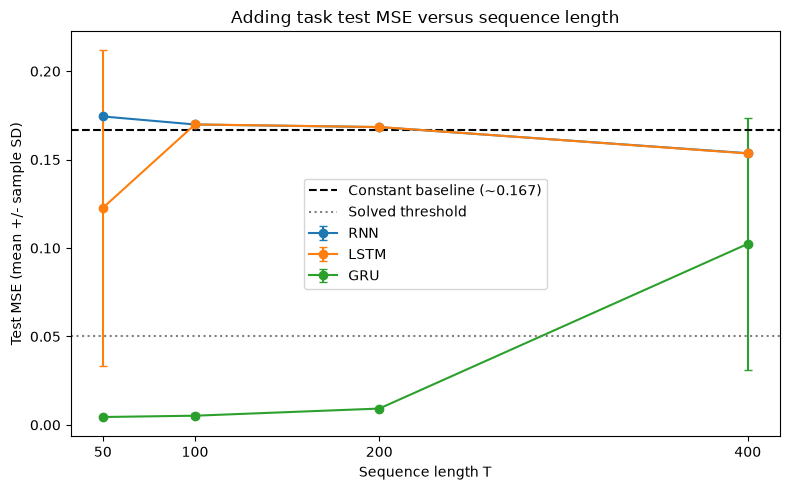

In [ ]:
def finish_adding_grid(epochs=EPOCHS_ADDING):
    """Resume only missing runs, then summarize all saved adding-task results."""
    results_path = PROJECT_ROOT / "results.csv"
    saved = pd.read_csv(results_path)
    completed = set(
        (str(row.model), int(row.seq_len), int(row.seed))
        for row in saved[saved["problem"] == "1_adding"].itertuples()
    )
    missing = [
        (model_name, sequence_length, seed)
        for sequence_length in (50, 100, 200, 400)
        for model_name in ("RNN", "LSTM", "GRU")
        for seed in MODEL_SEEDS
        if (model_name, sequence_length, seed) not in completed
    ]
    print(f"Resuming {len(missing)} missing adding-task runs.")

    for model_name, sequence_length, seed in missing:
        set_all_seeds(seed)
        train_loader = adding_loader(sequence_length, "train")
        validation_loader = adding_loader(sequence_length, "val")
        test_loader = adding_loader(sequence_length, "test")
        model = AddingRegressor(model_name).to(DEVICE)
        optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE)
        best_state, best_validation = None, float("inf")
        epoch_seconds = []
        for _ in range(epochs):
            started = time.perf_counter()
            training_loss = regression_epoch(model, train_loader, optimizer)
            epoch_seconds.append(time.perf_counter() - started)
            validation_loss = regression_epoch(model, validation_loader)
            if validation_loss < best_validation:
                best_validation = validation_loss
                best_state = copy.deepcopy(model.state_dict())
        model.load_state_dict(best_state)
        test_mse = regression_epoch(model, test_loader)
        save_result({
            "problem": "1_adding", "model": model_name, "seed": seed,
            "seq_len": sequence_length, "test_mse": test_mse,
            "params": sum(parameter.numel() for parameter in model.parameters()),
            "sec_per_epoch": float(np.mean(epoch_seconds)),
            "notes": f"h={HIDDEN_SIZE}; Adam lr={LEARNING_RATE}; epochs={epochs}; resumed run",
        })
        print(f"T={sequence_length} {model_name} seed={seed}: test MSE={test_mse:.5f}")

    saved = pd.read_csv(results_path)
    adding = saved[saved["problem"] == "1_adding"].copy()
    summary = adding.groupby(["model", "seq_len"]).agg(
        test_mse_mean=("test_mse", "mean"),
        test_mse_std=("test_mse", "std"),
        solved_runs=("test_mse", lambda values: int((values < 0.05).sum())),
        params=("params", "first"),
        sec_per_epoch=("sec_per_epoch", "mean"),
    )
    assert len(adding) == 36, f"Expected 36 unique adding runs; found {len(adding)}"
    display(summary)

    figure, axis = plt.subplots(figsize=(8, 5))
    for model_name in ("RNN", "LSTM", "GRU"):
        model_rows = adding[adding["model"] == model_name]
        aggregate = model_rows.groupby("seq_len")["test_mse"].agg(["mean", "std"])
        axis.errorbar(aggregate.index, aggregate["mean"], yerr=aggregate["std"],
                      marker="o", capsize=3, label=model_name)
    axis.axhline(1 / 6, color="black", linestyle="--", label="Constant baseline (~0.167)")
    axis.axhline(0.05, color="grey", linestyle=":", label="Solved threshold")
    axis.set_xticks((50, 100, 200, 400))
    axis.set_xlabel("Sequence length T")
    axis.set_ylabel("Test MSE (mean +/- sample SD)")
    axis.set_title("Adding task test MSE versus sequence length")
    axis.legend()
    figure.tight_layout()
    figure.savefig(PROJECT_ROOT / "problem1" / "figures" / "adding_mse_by_length.png", dpi=160)
    plt.show()
    plt.close(figure)
    return summary


adding_summary = finish_adding_grid()